Размер изображения: (512, 512)


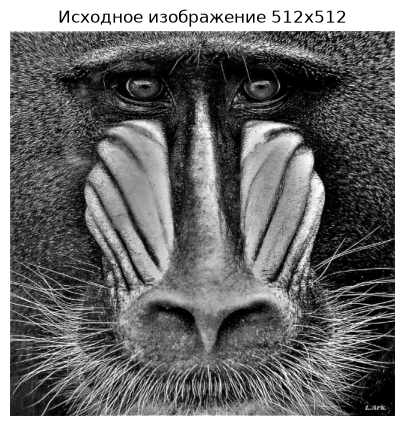

In [57]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('Monkey.jpg', cv2.IMREAD_GRAYSCALE)

if img is None:
    print('Ошибка: изображение не найдено')
else:
    # Принудительно меняем размер на 512x512
    img = cv2.resize(img, (512, 512))
    print('Размер изображения:', img.shape)
    
plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение 512x512')
plt.axis('off')
plt.show()

In [58]:
#Функции прямого и обратного преобразования хаара
def haar_step(a):
    p = a[0::2, 0::2]
    q = a[0::2, 1::2]
    r = a[1::2, 0::2]
    s = a[1::2, 1::2]

    ll = (p + q + r + s) / 2
    lh = (p - q + r - s) / 2
    hl = (p + q - r - s) / 2
    hh = (p - q - r + s) / 2

    n = a.shape[0] // 2
    res = np.zeros_like(a, dtype=np.float32)

    res[:n, :n] = ll
    res[:n, n:] = lh
    res[n:, :n] = hl
    res[n:, n:] = hh

    return res

def haar_inv_step(a):
    a = a.astype(np.float32)
    n, m = a.shape[0] // 2, a.shape[1] // 2
    
    ll = a[:n, :m]
    lh = a[:n, m:]
    hl = a[n:, :m]
    hh = a[n:, m:]

    # Выходной массив ТОГО ЖЕ размера, что и входной!
    res = np.zeros_like(a, dtype=np.float32)
    
    # Просто раскладываем пиксели по своим местам (шаг 2)
    res[0::2, 0::2] = (ll + lh + hl + hh) / 2.0
    res[0::2, 1::2] = (ll - lh + hl - hh) / 2.0
    res[1::2, 0::2] = (ll + lh - hl - hh) / 2.0
    res[1::2, 1::2] = (ll - lh - hl + hh) / 2.0
    
    return res


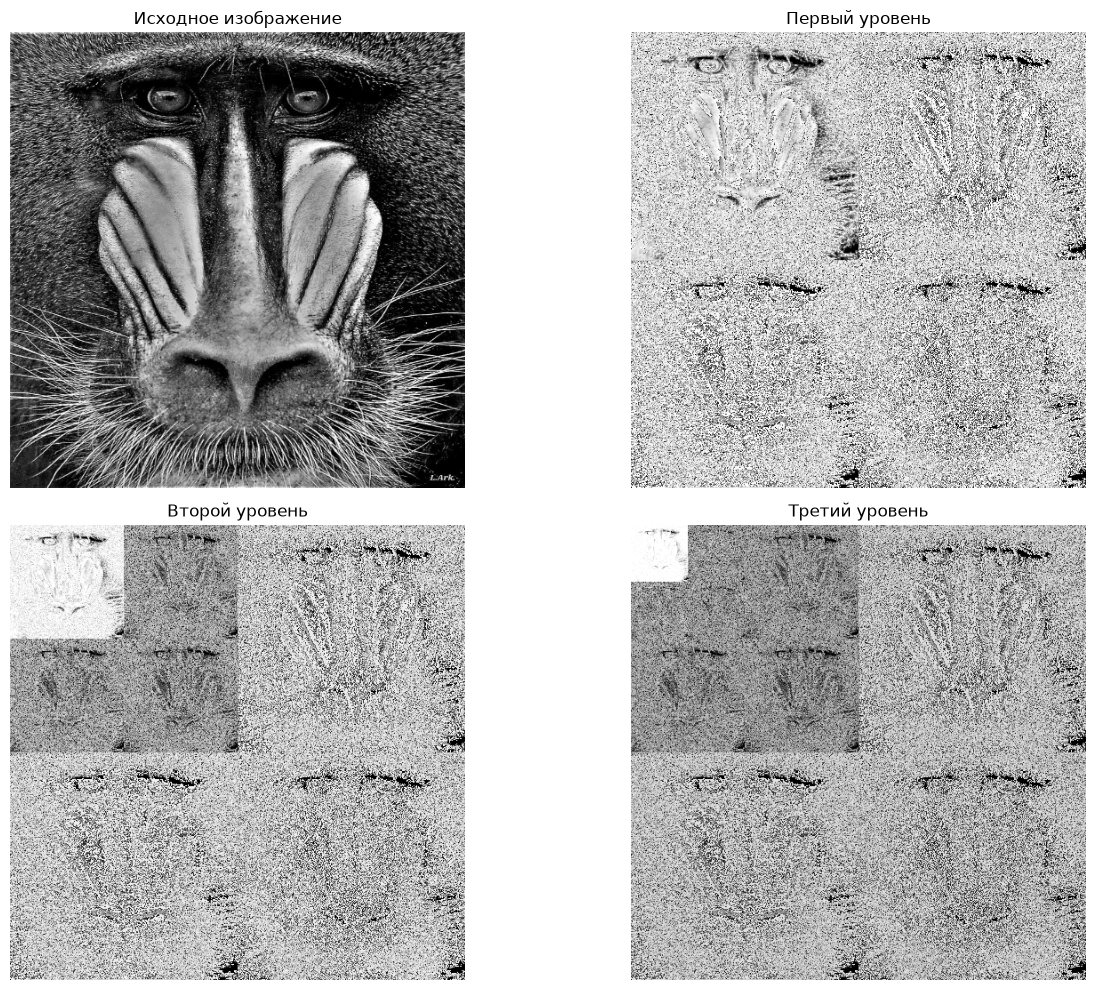

In [59]:
plt.figure(figsize=(14, 10))

for i, (c, name) in enumerate([
    (img, 'Исходное изображение'),
    (c1, 'Первый уровень'),
    (c2, 'Второй уровень'),
    (c3, 'Третий уровень')
]):
    plt.subplot(2, 2, i + 1)

    if i == 0:
        plt.imshow(c, cmap='gray', vmin=0, vmax=255)
    else:
        spec = np.log1p(np.abs(c))
        vmax = np.percentile(spec, 99)
        plt.imshow(spec, cmap='gray', vmin=0, vmax=vmax)

    plt.title(name)
    plt.axis('off')

plt.tight_layout()
plt.show()

Оставлено: 16997 из 262144


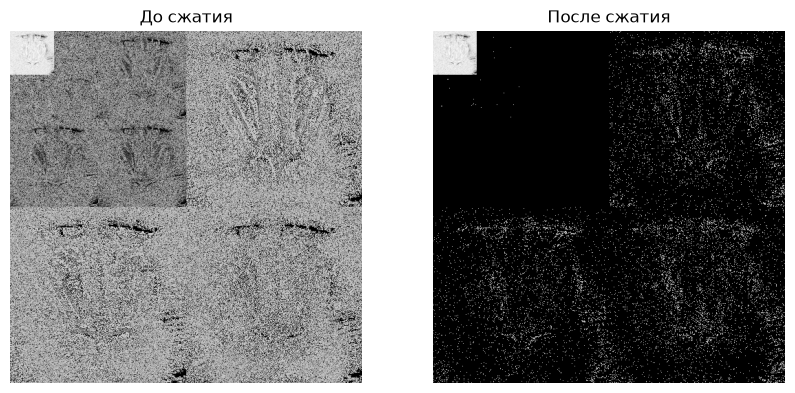

In [60]:
coef = c3.copy()
mask = np.ones(coef.shape, dtype=bool)
mask[:64, :64] = False # защищаем центр (аппроксимацию) от зануления

pos = np.flatnonzero(mask)
vals = coef.ravel()[pos]
keep = int(len(vals) * 0.05) # оставляем 5% деталей

idx = np.argpartition(np.abs(vals), -keep)[-keep:]

compressed = np.zeros_like(coef)
# --- ЭТА СТРОКА БЫЛА ПРОПУЩЕНА РАНЬШЕ ---
compressed[:64, :64] = coef[:64, :64] 
# ----------------------------------------
compressed.ravel()[pos[idx]] = vals[idx]

print('Оставлено:', np.count_nonzero(compressed), 'из', coef.size)

plt.figure(figsize=(10, 5))
plt.subplot(121); plt.imshow(np.log1p(np.abs(coef)), cmap='gray'); plt.title('До сжатия'); plt.axis('off')
plt.subplot(122); plt.imshow(np.log1p(np.abs(compressed)), cmap='gray'); plt.title('После сжатия'); plt.axis('off')
plt.show()

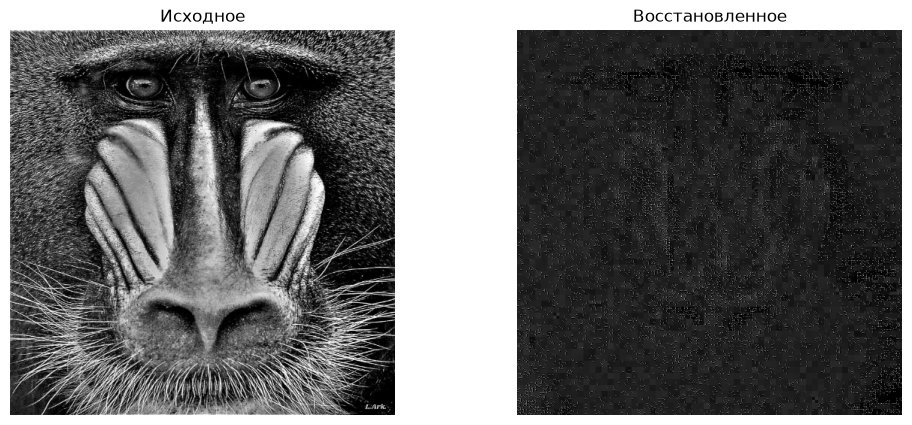

In [61]:
# Восстанавливаем 3-й уровень: передаем блок 128x128 (внутри которого лежат коэффициенты)
# и получаем обратно блок 128x128, но уже с восстановленными пикселями
restored = compressed.copy()

# Шаг 1: восстанавливаем 3-й уровень (блок 128x128)
restored[:128, :128] = haar_inv_step(restored[:128, :128])

# Шаг 2: восстанавливаем 2-й уровень (блок 256x256)
restored[:256, :256] = haar_inv_step(restored[:256, :256])

# Шаг 3: восстанавливаем 1-й уровень (всё изображение 512x512)
restored = haar_inv_step(restored)

restored = np.clip(restored, 0, 255).astype(np.uint8)

# Визуализация
plt.figure(figsize=(12, 5))
plt.subplot(121); plt.imshow(img, cmap='gray', vmin=0, vmax=255); plt.title('Исходное'); plt.axis('off')
plt.subplot(122); plt.imshow(restored, cmap='gray', vmin=0, vmax=255); plt.title('Восстановленное'); plt.axis('off')
plt.show()

MSE: 7895.32
PSNR: 9.16 дБ


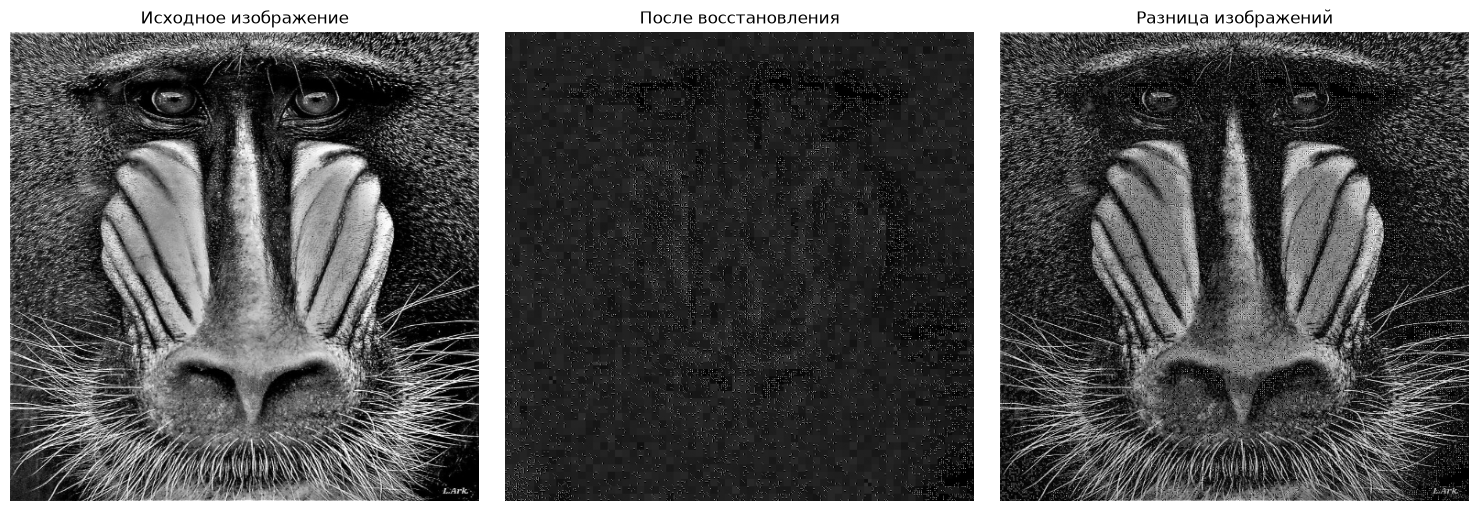

In [37]:
#Сравнение
mse = np.mean((img - restored.astype(np.float32)) ** 2)

if mse == 0:
    psnr = float('inf')
else:
    psnr = 10 * np.log10(255 ** 2 / mse)

print('MSE:', round(mse, 2))
print('PSNR:', round(psnr, 2), 'дБ')

diff = cv.absdiff(img.astype(np.uint8), restored)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(132)
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.title('После восстановления')
plt.axis('off')

plt.subplot(133)
plt.imshow(diff, cmap='gray')
plt.title('Разница изображений')
plt.axis('off')

plt.tight_layout()
plt.show()
